Explore the resampling in chunks.

Chunks are fixed on Healpix side rather than SWOT data.

In [1]:
%matplotlib inline

import logging

import cartopy.crs as ccrs
import healpix_geo.nested
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from healpix_resample import PSFResampler, NearestResampler, subset_for_parent_cell
from matplotlib.collections import PolyCollection

from swot_healpix.data import SWOT

log = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO)

In [2]:
# 15: 198m
# 10: 6.3km
level = 15

track = SWOT(cycle=546, track=19, version="PGC0")

In [3]:
swot_file = track.get_file()
swath = xr.open_dataset(swot_file, group="left", chunks=-1)

swath = swath.isel(num_lines=slice(20_000, 22_000))

# Left swath, we flip to have ascending longitude
swath = swath.isel(num_pixels=slice(None, None, -1))
if track.pass_type == "descending":
    swath = swath.isel(num_lines=slice(None, None, -1))

swath.longitude.load()
swath.latitude.load()
swath.ssh_karin_2.load()

swath = swath.dropna("num_lines", how="all", subset=["longitude"])
swath = swath.dropna("num_pixels", how="all", subset=["longitude"])
swath_clean = swath.dropna("num_pixels", how="all", subset=["longitude"])
swath_coarse = swath_clean.coarsen(num_lines=64, num_pixels=16, boundary="trim").mean()

swath

KeyboardInterrupt: 

Find chunks that fall in the swot track by defining a bounding polygon

In [ ]:
level_chunk = level - 7

In [6]:
bound_line_step = 1000  # Interval at which to compute bounding polygon along-track
bound_line_indices = np.arange(0, swath.num_lines.size, bound_line_step)
# always add last line
bound_line_indices = np.append(bound_line_indices, [swath.num_lines.size-1])

vertices_left_list = []
vertices_right_list = []
for bound_line in bound_line_indices:
    line = swath.isel(num_lines=bound_line)

    # Remove invalid coordinates
    line = line.dropna("num_pixels", subset=["longitude"])
    if line.num_pixels.size == 0:
        continue
    left = line.isel(num_pixels=0)
    right = line.isel(num_pixels=-1)
    vertices_left_list.append([float(left.longitude), float(left.latitude)])
    vertices_right_list.append([float(right.longitude), float(right.latitude)])

vertices_left = np.asarray(vertices_left_list)
vertices_right = np.asarray(vertices_right_list)

In [7]:
# enlarge slightly around center line
swath_center = vertices_left + vertices_right
delta_left = swath_center - vertices_left
delta_right = vertices_right - swath_center
vertices_left -= delta_left / 10000
vertices_right -= delta_right / 10000

vertices = np.concatenate([vertices_left, vertices_right[::-1]])

In [8]:
chunk_ids, *_ = healpix_geo.nested.polygon_coverage(
    vertices, depth=level_chunk, ellipsoid="WGS84"
)

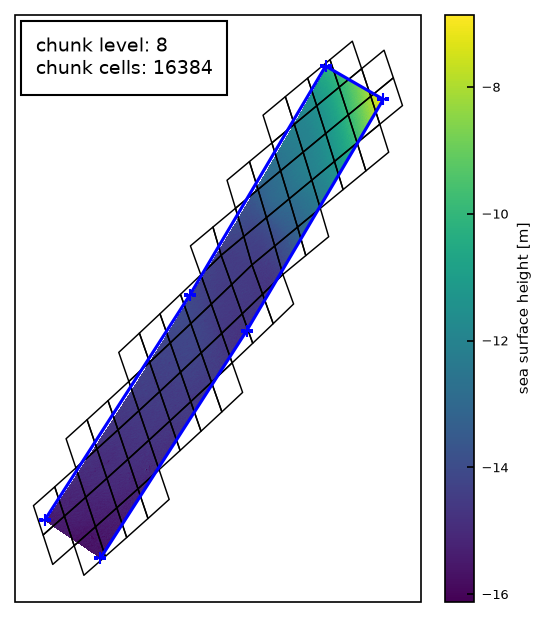

In [20]:
fig, ax = plt.subplots(
    figsize=(4, 4),
    layout="constrained",
    dpi=150,
    subplot_kw={"projection": ccrs.ObliqueMercator(central_longitude=120, azimuth=45)},
)

swath.ssh_karin_2.plot.pcolormesh(
    x="longitude", y="latitude", transform=ccrs.PlateCarree(), center=False
)
ax.plot(*vertices.T, color="b", marker="+", transform=ccrs.PlateCarree())
# ax.set_global()

vertices_chunk = np.stack(
    healpix_geo.nested.vertices(chunk_ids, depth=level_chunk, ellipsoid="WGS84"),
    axis=-1,
)
polys = PolyCollection(vertices_chunk, ec="k", fc="none", lw=0.7, transform=ccrs.PlateCarree())
ax.add_collection(polys)

ax.coastlines(resolution="110m")

pad = 7
ax.annotate(
    f"chunk level: {level_chunk}\nchunk cells: {4**(level-level_chunk)}",
    xy=(0, 1),
    xycoords="axes fraction",
    xytext=(pad+3, -pad-3),
    textcoords="offset points",
    ha="left",
    va="top",
    bbox=dict(pad=pad, ec="k", fc="none"),
)
ax.set_aspect("equal")

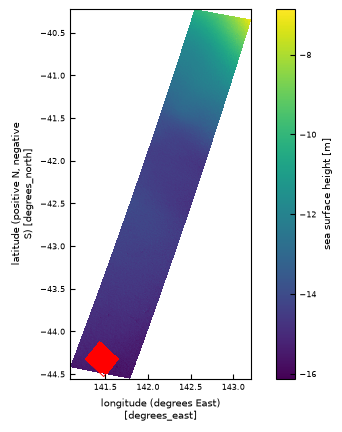

In [9]:
i_chunk = 5
chunk_id = chunk_ids[i_chunk]

lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
ssh = swath.ssh_karin_2.values.ravel()

index_sub, out_ids = subset_for_parent_cell(
    lon,
    lat,
    chunk_id,
    level_parent=level_chunk,
    level=level,
    margin_rings=3,
)

fig, ax = plt.subplots()

swath.ssh_karin_2.plot.pcolormesh(x="longitude", y="latitude")

vertices_chunk = np.stack(
    healpix_geo.nested.vertices(chunk_id, depth=level_chunk, ellipsoid="WGS84"),
    axis=-1,
)
polys = PolyCollection(vertices_chunk, ec="r", fc="none", lw=0.7)
ax.add_collection(polys)
ax.set_aspect("equal")

ax.plot(lon[index_sub], lat[index_sub], ls="", marker=",", color="r")

In [22]:
lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
ssh = swath.ssh_karin_2.values.ravel()

result_by_chunk = []
for i_chunk, chunk_id in enumerate(chunk_ids):
    log.info("%d/%d", i_chunk+1, len(chunk_ids))

    index_sub, out_ids = subset_for_parent_cell(
        lon,
        lat,
        chunk_id,
        level_parent=level_chunk,
        level=level,
        margin_rings=3,
    )

    try:
        resampler = PSFResampler(
            lon_deg=lon[index_sub],
            lat_deg=lat[index_sub],
            level=level,
            out_cell_ids=out_ids,
            verbose=False,
        )
    except RuntimeError:
        continue

    result = resampler.resample(ssh[index_sub], lam=0.7)
    ssh_hp = xr.DataArray(
        result.cell_data, dims=("cell_ids",), coords={"cell_ids": result.cell_ids}
    )
    result_by_chunk.append(ssh_hp)

ssh_hp = xr.concat(result_by_chunk, "cell_ids")

INFO:__main__:1/69
INFO:__main__:2/69
INFO:__main__:3/69
INFO:__main__:4/69
INFO:__main__:5/69
INFO:__main__:6/69
INFO:__main__:7/69
INFO:__main__:8/69
INFO:__main__:9/69
INFO:__main__:10/69


KeyboardInterrupt: 

In [17]:
fig, axes = plt.subplots(1, 2, layout="constrained", sharex=True, sharey=True)
ax1, ax2 = axes

ssh_vmin = float(swath.ssh_karin_2.quantile(0.01))
ssh_vmax = float(swath.ssh_karin_2.quantile(0.99))

swath.ssh_karin_2.plot.pcolormesh(
    x="longitude", y="latitude", vmin=ssh_vmin, vmax=ssh_vmax, ax=ax1
)

vertices = np.stack(
    healpix_geo.nested.vertices(ssh_hp.cell_ids, depth=level, ellipsoid="WGS84"),
    axis=-1,
)
colorizer = plt.Colorizer(cmap="viridis", norm=plt.Normalize(ssh_vmin, ssh_vmax))
colors = colorizer.to_rgba(ssh_hp.values)
polys = PolyCollection(vertices[:-1], ec=colors, fc=colors)
ax2.add_collection(polys)